# Predicting Iris Flower Species with Machine Learning
### DATASCI 530 · Assignment 5 · Whitney Barr


**Key findings**
- The data contain **150 flowers, 4 features, and 3 equally sized classes** (33.3% each).
- Using cross-validation, the **SVM (96.7% accuracy), random forest (96.7%), and tuned neural network (97.3%)** perform almost identically.The ridge classifier is less accurate at 82%.
- **The support vector machine method is recommended.** The neural network is a close second.
- **New insight** *Iris-setosa* is completely separable from the other two species using petal measurements, whereas *Iris-versicolor* and *Iris-virginica* overlap. This is where classification is hardest.


## 1. Setup

The neural network, random forest, and ridge classifier come from the same `sklearn` package as the SVM, so they are fitted and evaluated with the same syntax.

In [1]:
# Import the package for the University of California Irvine API
from ucimlrepo import fetch_ucirepo

# Import SK-Learn library for machine learning functions
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_validate
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import RidgeClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Import standard data analysis packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Dataset Description

The Iris dataset comes from the UC Irvine Machine Learning Repository (id = 53). 

- `X` is the feature matrix: four flower measurements in centimeters.
- `y` is the label I want to predict: the flower species ("class").

The photo below shows the three species. The four features are the length and width of the sepals (the outer leaves of the flower) and of the petals.

![Photos of the three iris species: Iris Versicolor, Iris Setosa and Iris Virginica, with a sepal and a petal labeled](iris_species.png)

In [2]:
# Fetch data from the UC Irvine Machine Learning Repository API
iris = fetch_ucirepo(id=53)

# Extract features (X) and label (y)
X = iris.data.features
y = iris.data.targets["class"]

### a) Size of the dataset

Number of rows (flowers) and number of features:

In [3]:
print("Number of rows:", len(X))
print("Number of features:", X.shape[1])
print("Feature names:", list(X.columns))

Number of rows: 150
Number of features: 4
Feature names: ['sepal length', 'sepal width', 'petal length', 'petal width']


### b) Proportion of observations in each class

In [4]:
# Compute frequency table for the label
table_y = pd.crosstab(y, "proportion") / len(y)

table_y_pretty = table_y.rename_axis(index = "Species", columns = None).reset_index()

table_y_pretty.style.format({"proportion": "{:.1%}"}).hide(axis = "index").set_caption("Proportion of observations by class")

Species,proportion
Iris-setosa,33.3%
Iris-versicolor,33.3%
Iris-virginica,33.3%


The three classes are perfectly balanced (50 flowers each), so accuracy is a fair metric here.

### 2.3 Quality checks

Before modeling, I check for missing values and look at basic descriptive statistics.

In [5]:
# Count missing values in each feature
print("Missing values per feature:")
print(X.isna().sum())
print("Missing values in the label:", y.isna().sum())

Missing values per feature:
sepal length    0
sepal width     0
petal length    0
petal width     0
dtype: int64
Missing values in the label: 0


In [6]:
# Descriptive statistics of the features
X.describe().round(2).style.format("{:.2f}").set_caption("Descriptive statistics of the features (cm)")

,sepal length,sepal width,petal length,petal width
count,150.00,150.00,150.00,150.00
mean,5.84,3.05,3.76,1.20
std,0.83,0.43,1.76,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


## 3. Comparison of Machine Learning Methods

### 3.1 Methodology

- **Methods** -  support vector machine (SVM), random forest, neural network, and a **ridge classifier** (the additional method and a linear model).
- **Cross-validation.** I evaluate every method with 5-fold cross-validation (`cv=5`).
- **Scaling** -  the SVM, neural network and ridge classifier are sensitive to the scale of the features, so they are placed in a `Pipeline` with a `StandardScaler`. In a pipeline the scaler is learned *only from the training folds* in each round of cross-validation, so no information from the held-out fold leaks into the model. The random forest does not need scaling.
- **Metrics** - accuracy, and *macro-averaged* precision, recall and F1. "Macro" computes the metric for each species and then averages the three, treating all species equally.
- **Tuning** - all methods use their **default tuning parameters except the neural network**, which is the one method I tune (Section 3.3). 

### 3.2 Methods with default settings

`random_state = 0` is set so that the results are reproducible.

In [7]:
# Metrics to compute in cross-validation
metrics = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]

# SVM with default parameters (scaled features)
pipe_svm = Pipeline([("scaler", StandardScaler()),
                     ("svm", SVC())])

# Ridge classifier with default parameters (scaled features)
pipe_ridge = Pipeline([("scaler", StandardScaler()),
                       ("ridge", RidgeClassifier())])

# Random forest with default parameters
rf = RandomForestClassifier(random_state = 0)

res_svm   = cross_validate(pipe_svm,   X, y, scoring = metrics, cv = 5)
res_ridge = cross_validate(pipe_ridge, X, y, scoring = metrics, cv = 5)
res_rf    = cross_validate(rf,         X, y, scoring = metrics, cv = 5)

### 3.3 Tuning the neural network

For the neural network I define a **grid of tuning parameters** and let cross-validation select the best combination. The main design choices of a neural network are the number of units and the number of hidden layers, so the grid compares:

- one hidden layer with 10, 50 or 100 units, and
- two hidden layers with 10 units each

The maximum number of training iterations is set to 1000 for every candidate. With the default (200) the network did not finish converging and `sklearn` raised a convergence warning in each fold. This is a technical setting, not a tuning choice, so it is the same for all candidates.

In [8]:
# Neural network pipeline (scaled features)
pipe_nn = Pipeline([("scaler", StandardScaler()),
                    ("nn", MLPClassifier(random_state = 0))])

# Grid of tuning parameters: use the step name, two underscores, and the parameter name
param_grid = {"nn__hidden_layer_sizes": [(10,), (50,), (100,), (10, 10)],
              "nn__max_iter":           [1000]}

# Configure and run the grid search with 5-fold cross-validation
grid = GridSearchCV(pipe_nn, param_grid, cv = 5,
                    return_train_score = True,
                    n_jobs = -1)

grid.fit(X, y)

print("Best estimator:\n{}".format(grid.best_estimator_))

Best estimator:
Pipeline(steps=[('scaler', StandardScaler()),
                ('nn',
                 MLPClassifier(hidden_layer_sizes=(50,), max_iter=1000,
                               random_state=0))])


The best-performing neural network is the one printed above. I now compute all four metrics for this selected network with the same 5-fold cross-validation used for the other methods.

In [9]:
res_nn = cross_validate(grid.best_estimator_, X, y, scoring = metrics, cv = 5)

### 3.4 Results

In [10]:
# Average each metric across the 5 folds
results_table = pd.DataFrame({"SVM (default)":              pd.DataFrame(res_svm).mean(),
                              "Random forest (default)":    pd.DataFrame(res_rf).mean(),
                              "Neural network (tuned)":     pd.DataFrame(res_nn).mean(),
                              "Ridge classifier (default)": pd.DataFrame(res_ridge).mean()})

# Keep only the performance metrics and give them readable names
results_table = results_table.loc[["test_accuracy", "test_precision_macro", "test_recall_macro", "test_f1_macro"]]
results_table = results_table.rename(index = {"test_accuracy":        "Accuracy",
                                              "test_precision_macro": "Precision (macro)",
                                              "test_recall_macro":    "Recall (macro)",
                                              "test_f1_macro":        "F1 (macro)"})

results_table.style.format("{:.3f}").set_caption("5-fold cross-validated performance (average across folds)")

,SVM (default),Random forest (default),Neural network (tuned),Ridge classifier (default)
Accuracy,0.967,0.967,0.973,0.820
Precision (macro),0.968,0.971,0.976,0.829
Recall (macro),0.967,0.967,0.973,0.820
F1 (macro),0.967,0.966,0.973,0.818


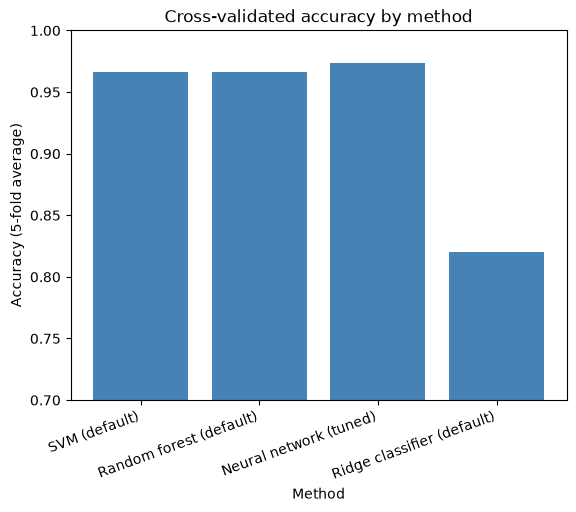

In [11]:
# Bar chart of cross-validated accuracy for each method
plt.bar(results_table.columns, results_table.loc["Accuracy"], color = "steelblue")
plt.ylim(0.7, 1.0)
plt.title("Cross-validated accuracy by method")
plt.xlabel("Method")
plt.ylabel("Accuracy (5-fold average)")
plt.xticks(rotation = 20, ha = "right")
plt.show()

**Interpretation**

- The **SVM, random forest, and tuned neural network are essentially tied**. Their accuracy ranges from 96.7% to 97.3%. With 150 flowers, a difference of 0.7 percentage points is **one flower**, which is well within the noise of cross-validation.
- The **ridge classifier is clearly worse** (82.0%). It is a linear method and cannot separate the two overlapping species as well as the other methods (see Section 4).
- Precision, recall, and F1 tell the same story as accuracy. This is expected because the classes are balanced.
- **Caveat** the neural network was selected using the same cross-validation that I report, so its score is slightly optimistic. The other three methods were not tuned, so their scores are not affected by this.
**The support vector machine method is recommended because** it performs as well as the best methods, does not need any tuning, and is simple and fast to fit. The neural network scores 0.7 points higher, but that is a one-flower difference that is not strong enough evidence to justify the extra tuning and complexity.

### 3.5 Check on held-out data (SVM)

As a final sanity check, the recommended SVM is fitted on 75% of the flowers and evaluated on the remaining 25%. The confusion matrix shows the proportion of all test flowers in each cell; the diagonal contains the correct predictions.

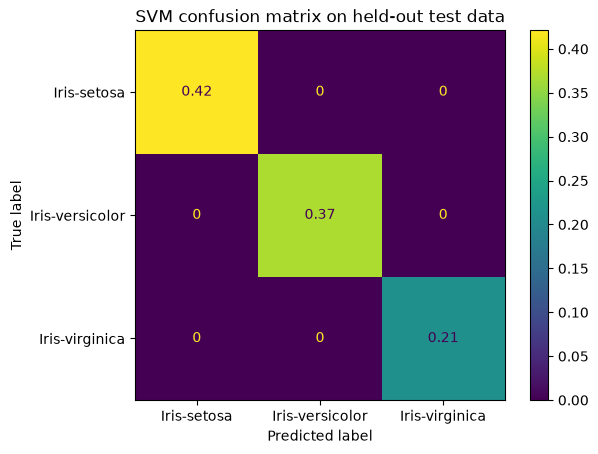

In [12]:
# Split into training and test data
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                   random_state = 104,
                                   test_size = 0.25,
                                   shuffle = True)

# Fit the pipeline (the scaler is learned from the training data only)
pipe_svm.fit(X_train, y_train)

# Out-of-sample predictions
predictions = pipe_svm.predict(X_test)

# Compute confusion matrix
cm = confusion_matrix(y_test, predictions, labels = pipe_svm.classes_) / len(y_test)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix = cm,
                              display_labels = pipe_svm.classes_)
disp.plot()
plt.title("SVM confusion matrix on held-out test data")
plt.show()

In [13]:
print("Test set size:", len(y_test))
print("Test accuracy:", round(pipe_svm.score(X_test, y_test), 3))

Test set size: 38
Test accuracy: 1.0


The SVM classifies every one of the 38 held-out flowers correctly. This is consistent with the cross-validation results, but a test set this small is not precise enough to rank methods, so the recommendation is based on cross-validation.

## 4. New Insight - What Separates the Species?

Why is it easy to classify some species and harder to classify others? I compute the average of each measurement by species, and plot the two petal measurements for all 150 flowers.

In [14]:
# Combine features and label, then compute the mean of each feature by species
iris_all = pd.concat([X, y], axis = 1)
means_table = iris_all.groupby("class").mean().round(2)

means_table.style.format("{:.2f}").set_caption("Average measurement by species (cm)")

,sepal length,sepal width,petal length,petal width
class,,,,
Iris-setosa,5.01,3.42,1.46,0.24
Iris-versicolor,5.94,2.77,4.26,1.33
Iris-virginica,6.59,2.97,5.55,2.03


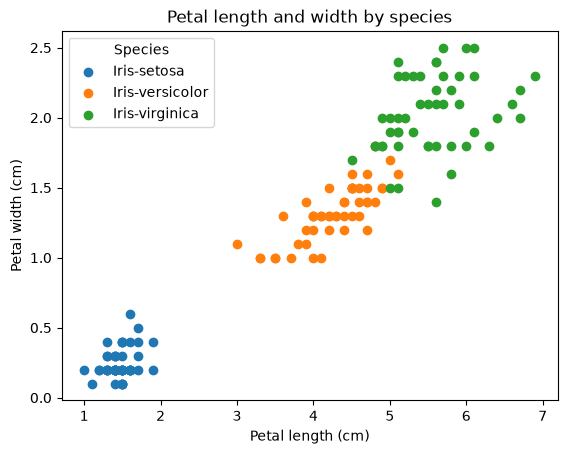

In [15]:
# Scatter plot of the petal measurements, one color per species
list_classes = ["Iris-setosa", "Iris-versicolor", "Iris-virginica"]

for species in list_classes:
    plt.scatter(x = X.loc[y == species, "petal length"],
                y = X.loc[y == species, "petal width"])

plt.legend(labels = list_classes, title = "Species")
plt.title("Petal length and width by species")
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.show()

## 5. What do we learn from it? 

- **Setosa is easy to identify.** Its petals are far smaller than those of the other species (average length 1.46 cm vs. 4.26 cm and 5.55 cm). In the scatter plot, setosa forms a cluster that is completely separate from the rest.
- **Versicolor and virginica overlap.** Their average petal length and width are closer to each other, and in the plot the two clouds touch in the middle. Flowers near that boundary are the ones that are hard to classify correctly.
- **This explains why several different methods reach a similar accuracy** of about 97%. They all separate setosa trivially and all struggle with the same few borderline versicolor/virginica flowers. The remaining errors come from these borderline flowers, not from the choice of method. This is an interpretation of the plot rather than something I tested directly.
- The ridge classifier uses a linear boundary and has more trouble with the overlapping region, which is consistent with its lower accuracy.

**Limitations** With only 150 flowers, small differences in accuracy between methods are not reliable, and results could change with a different random split. Only one method was tuned and only a small grid was searched. 

**Final recommendation** use the **SVM** because it matches the best cross-validated performance without tuning.